# Task 2

## Setting up

In [39]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score, KFold

In [40]:
# read in the data
train_in = pd.read_csv("data/train_in.csv")
train_in = train_in.to_numpy()

train_out = pd.read_csv("data/train_out.csv")
train_out = train_out.to_numpy() # these are the labels for training data
train_out = train_out.reshape(-1)

test_in = pd.read_csv("data/test_in.csv")
test_in = test_in.to_numpy()

test_out = pd.read_csv("data/test_out.csv")
test_out = test_out.to_numpy()

## Creating the functions

In [62]:
# Making all the MLP functions train, predict, evaluate, plot cm
def train_mlp(data, labels, n_features):
    W = np.zeros((n_features, 10))
    for i in range(len(data)):
        x = data[i].reshape(-1)
        scores = x @ W
        y_pred = scores.argmax()

        if y_pred != labels[i]:
            W[:, labels[i]] += x
            W[:, y_pred] -= x   

    return W # weight matrix

def predict_mlp(x, W):
    return (x @ W).argmax()

def evaluate_mlp(data, labels, W):
    predictions = np.array([predict_mlp(x, W) for x in data])
    return np.mean(predictions == labels) # accuracy

def cm_mlp(data, labels, W):
    predictions = np.array([predict_mlp(x, W) for x in data])
    cm = confusion_matrix(labels, predictions)
    plt.xlabel("Predicted labels")
    plt.ylabel("True labels")
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title(f"Confusion matrix")
    plt.colorbar()
    plt.show()

## Performance of 256x10 on test set

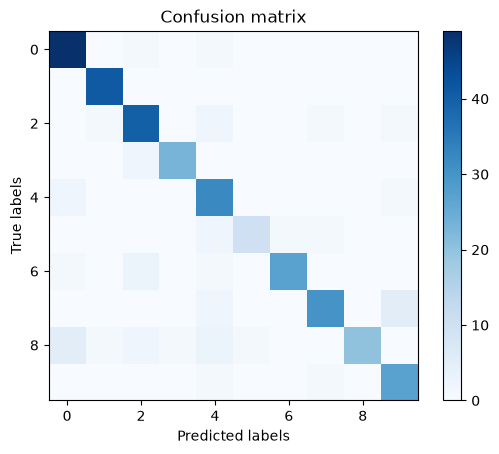

Fold 1 - Validation Accuracy: 0.8743


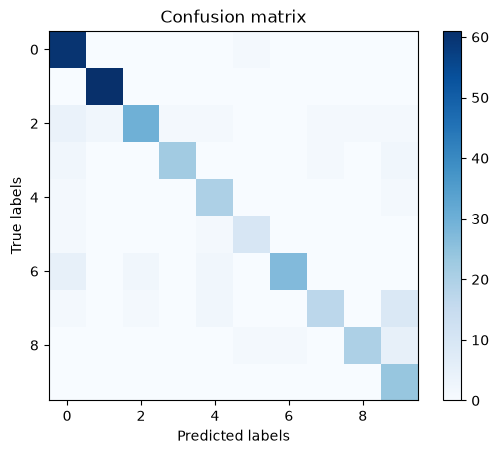

Fold 2 - Validation Accuracy: 0.8534


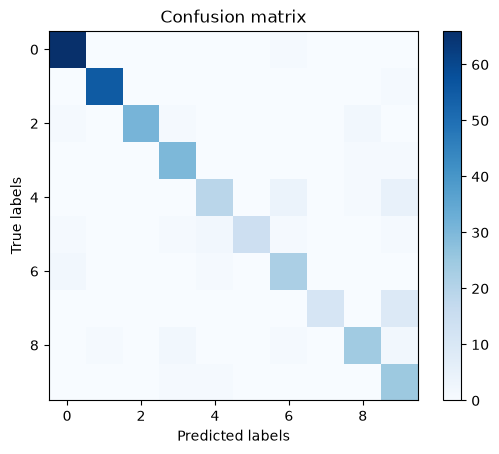

Fold 3 - Validation Accuracy: 0.8710


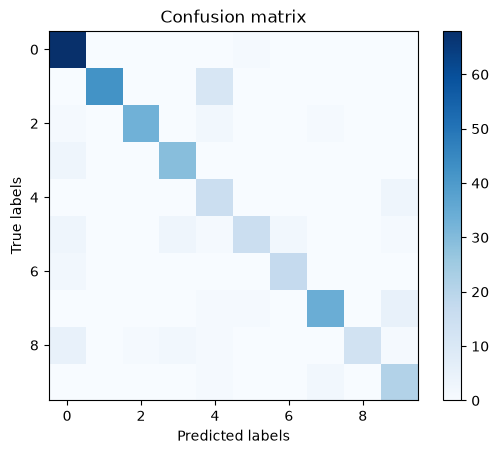

Fold 4 - Validation Accuracy: 0.8416


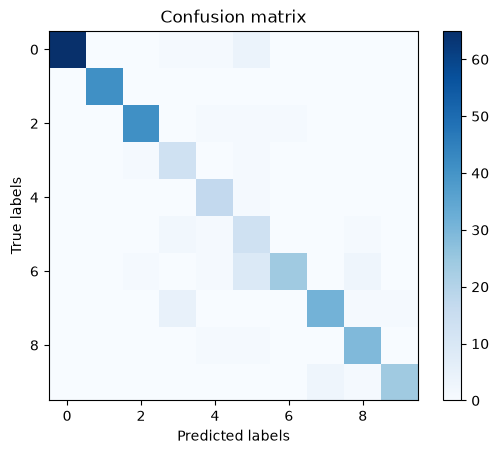

Fold 5 - Validation Accuracy: 0.8739


In [64]:
# 5-fold CV
def cross_validation(data, labels, n_features):
    N = len(labels)
    indices = np.arange(N)
    np.random.shuffle(indices)

    train_in_shuffled = data[indices]
    train_out_shuffled = labels[indices]

    folds = np.array_split(indices, 5)

    for k in range(5):
        validation_indices = folds[k]
        training_indices = np.concatenate([folds[i] for i in range(5) if i != k])

        x_train = train_in_shuffled[training_indices]
        y_train = train_out_shuffled[training_indices]

        x_val = train_in_shuffled[validation_indices]
        y_val = train_out_shuffled[validation_indices]

        # Train the model on the training data
        weights = train_mlp(x_train, y_train, n_features)

        # Evaluate the model on the validation data
        val_accuracy = evaluate_mlp(x_val, y_val, weights)
        cm_mlp(x_val, y_val, weights)

        print(f"Fold {k + 1} - Validation Accuracy: {val_accuracy:.4f}")

cross_validation(train_in, train_out, 256)

Test Accuracy: 0.1150


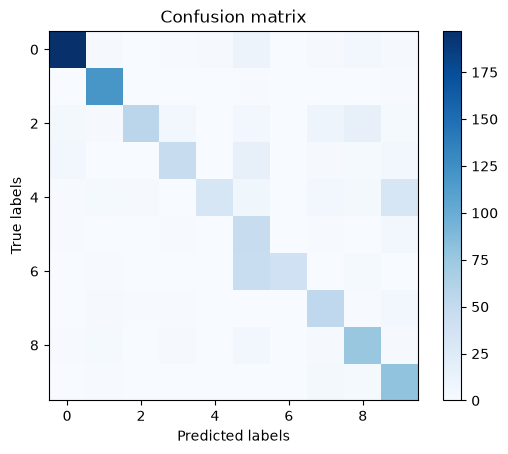

In [65]:
# evaluate performance on test data + plot alongside training data performance
final_weights = train_mlp(train_in, train_out, 256)
test_accuracy = evaluate_mlp(test_in, test_out, final_weights)
print(f"Test Accuracy: {test_accuracy:.4f}")
cm_mlp(test_in, test_out, final_weights)

## Performance of 257x10 (added bias) on test set

(1706, 257)
(999, 257)


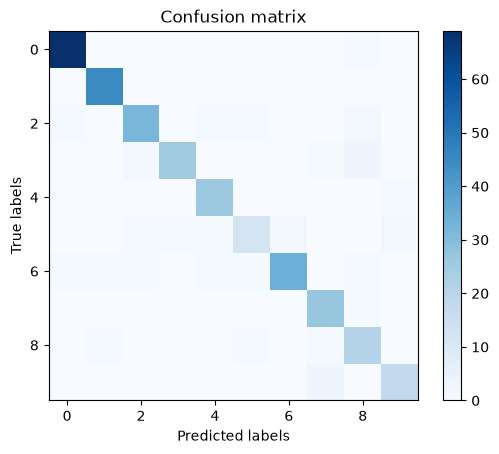

Fold 1 - Validation Accuracy: 0.9035


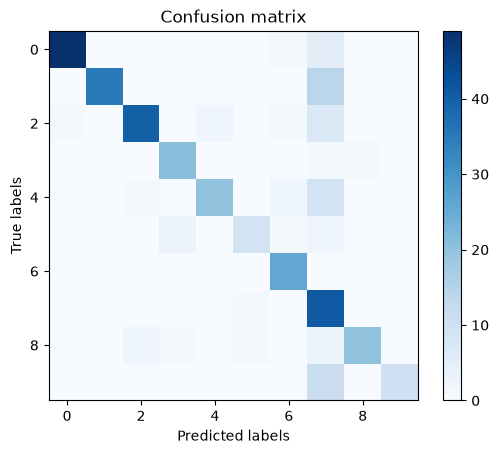

Fold 2 - Validation Accuracy: 0.7947


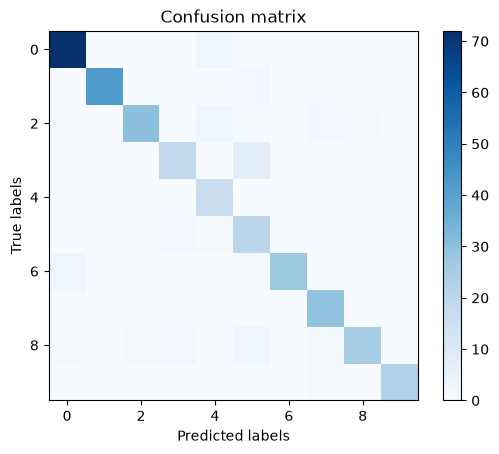

Fold 3 - Validation Accuracy: 0.8886


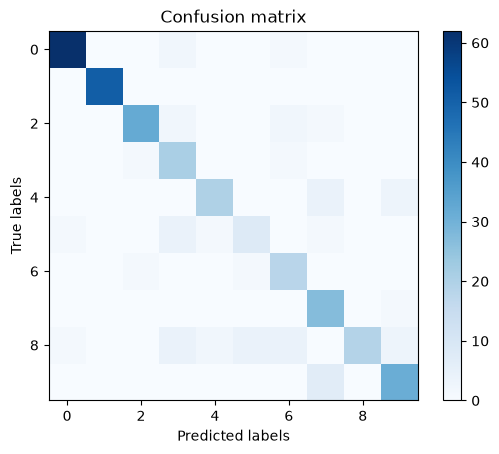

Fold 4 - Validation Accuracy: 0.8475


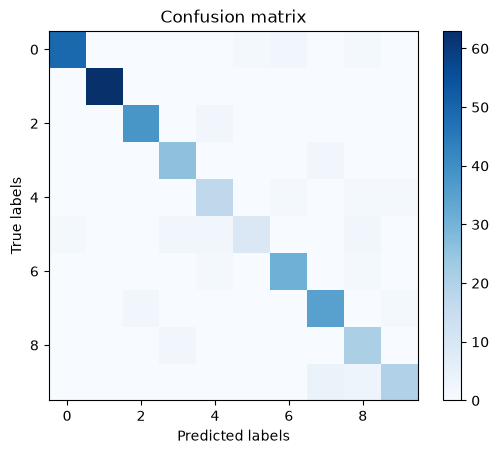

Fold 5 - Validation Accuracy: 0.9062
Test Accuracy: 0.1186


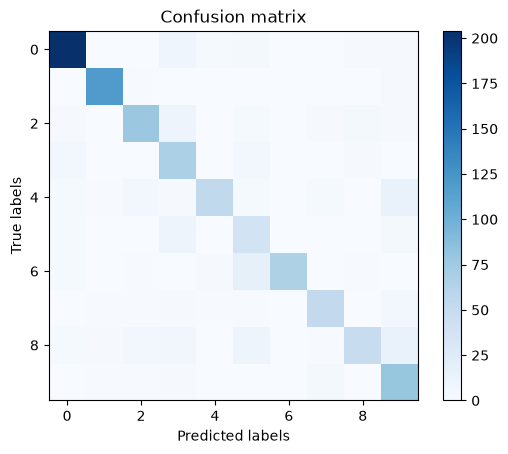

In [ ]:
# adding bias
bias_train = np.ones((train_in.shape[0], 1))
bias_test = np.ones((test_in.shape[0], 1))

train_in_bias = np.hstack((train_in, bias_train))
test_in_bias = np.hstack((test_in, bias_test))

# 5-fold CV to get an idea of the accuracy
cross_validation(train_in_bias, train_out, 257)

b_final_weights = train_mlp(train_in_bias, train_out, 257)
b_test_accuracy = evaluate_mlp(test_in_bias, test_out, b_final_weights)
print(f"Test Accuracy: {b_test_accuracy:.4f}")
cm_mlp(test_in_bias, test_out, b_final_weights)

## Another try with 10 epochs